# 初期平均フォノン数と誤差生成子の主要10項
角度校正前で保存した CPTP 射影済みの $\chi$ 行列を使い、各 $\bar n$ で Pauli transfer matrix の対数を H/S/C/A 基底に分解する。指定の5項を含め、残り5項は校正前のスイープ全体での最大絶対値が大きい順に選ぶ。表と図は選んだ10項を同じ基準で降順に並べ、値の符号を保持する。

In [8]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from scipy.linalg import logm
import numpy as np

from drive_calibration_qpt_analysis import _chi_raw_to_superoperator
from ms_gate_functions import superoperator_to_ptm
from noise_error_structure import _decompose_generator_taxonomy

source = Path("results/calibration_channel_comparison/projected_chi_before_after.npz")
records = []
with np.load(source) as data:
    chis = data["chi_before"]
    nbars = data["n_bar"]
    if len(chis) != len(nbars):
        raise ValueError("Unexpected number of pre-calibration channels")
    for nbar, chi in zip(nbars, chis):
        # 保存された trace-one χ を QuTiP の2量子ビット規約に戻す。
        channel = _chi_raw_to_superoperator(16 * chi)
        generator = logm(superoperator_to_ptm(channel)).real
        fit = _decompose_generator_taxonomy(generator)
        for (sector, mode), value in zip(fit["metadata"], fit["coefficients"]):
            records.append((nbar, f"{sector}:{mode}", value))

values = pd.DataFrame(records, columns=["n_bar", "term", "value"])
sweep = values.pivot(index="term", columns="n_bar", values="value").sort_index(axis=1)

In [9]:
required = ["H:XX", "S:XX", "S:IX", "S:XI", "C:IX,XI"]
peak = sweep.abs().max(axis=1)
extra = peak.drop(required).nlargest(5).index.tolist()
order = peak.loc[required + extra].sort_values(ascending=False, kind="stable").index
summary = sweep.loc[order].copy()
summary.insert(0, "max |coefficient|", peak.loc[order])
summary.style.format("{:.4e}").set_caption("校正前の係数（1ゲートあたり）と初期平均フォノン数")

n_bar,max |coefficient|,0.010000,1.000000,2.000000,4.000000,6.000000,8.000000,10.000000
term,,,,,,,,
H:XX,1.5244e-01,1.3736e-02,2.8806e-02,4.3740e-02,7.2711e-02,1.0046e-01,1.2702e-01,1.5244e-01
S:XX,1.8698e-02,1.6386e-04,6.1588e-04,1.4847e-03,4.2931e-03,8.2741e-03,1.3153e-02,1.8698e-02
S:XI,4.6679e-03,5.5061e-04,1.0704e-03,1.5667e-03,2.4762e-03,3.2901e-03,4.0178e-03,4.6679e-03
S:IX,4.6679e-03,5.5061e-04,1.0704e-03,1.5667e-03,2.4762e-03,3.2901e-03,4.0178e-03,4.6679e-03
"C:IX,XI",4.6429e-03,5.2562e-04,1.0454e-03,1.5417e-03,2.4512e-03,3.2651e-03,3.9928e-03,4.6429e-03
S:IZ,1.7451e-04,1.7451e-04,1.5044e-04,1.4392e-04,1.3862e-04,1.3613e-04,1.3461e-04,1.3353e-04
S:ZI,1.7451e-04,1.7451e-04,1.5044e-04,1.4392e-04,1.3862e-04,1.3614e-04,1.3462e-04,1.3352e-04
S:YX,1.7450e-04,1.7450e-04,1.5042e-04,1.4390e-04,1.3860e-04,1.3604e-04,1.3450e-04,1.3348e-04
S:XY,1.7450e-04,1.7450e-04,1.5042e-04,1.4391e-04,1.3861e-04,1.3606e-04,1.3451e-04,1.3349e-04


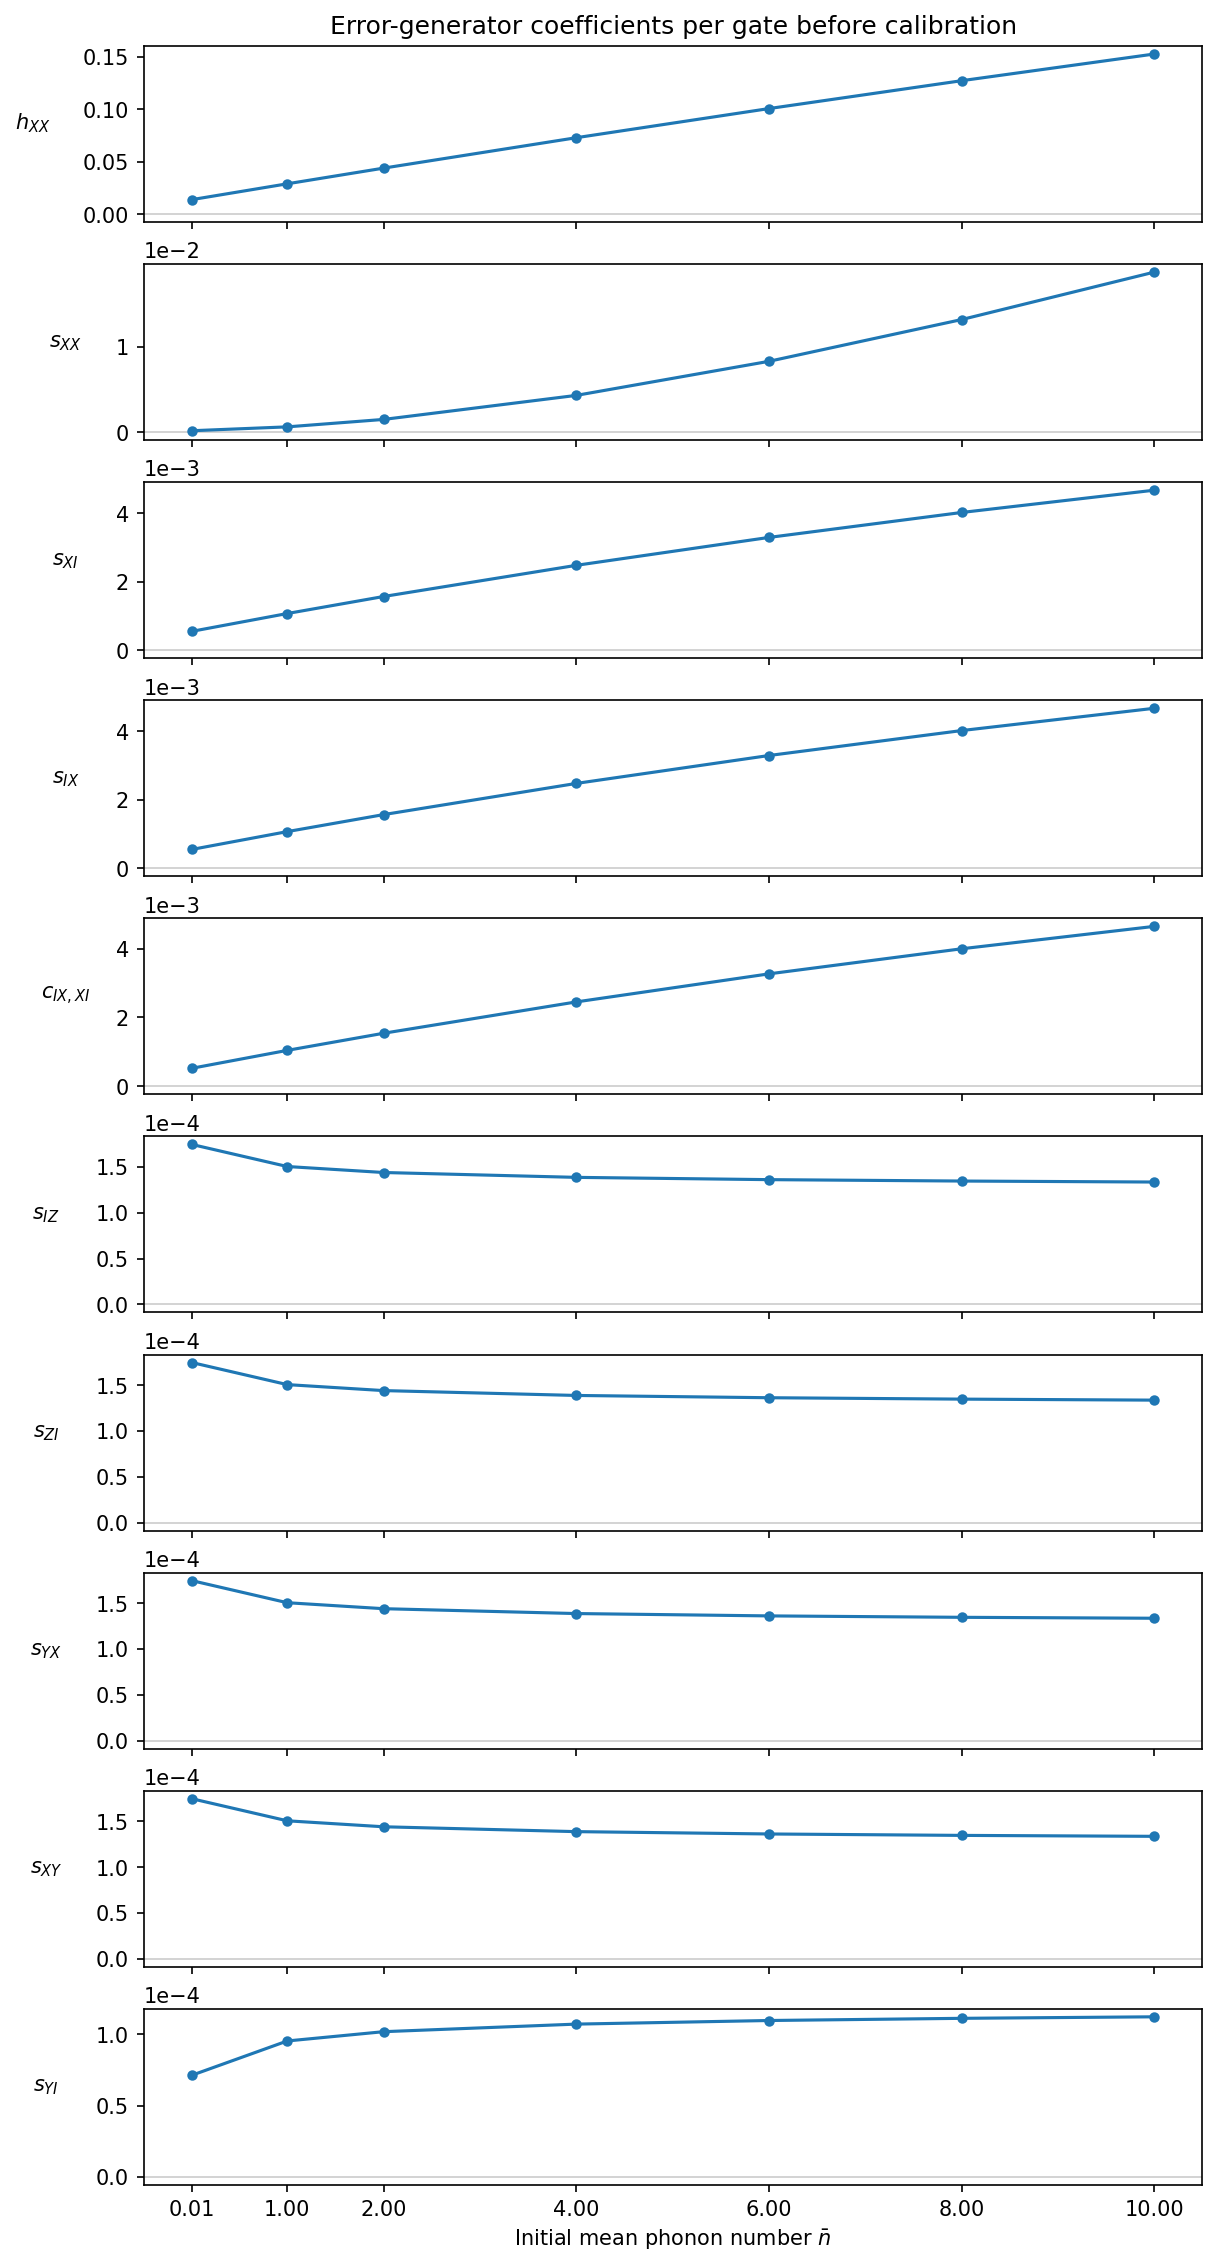

In [11]:
fig, axes = plt.subplots(len(order), 1, figsize=(8, 15), sharex=True, layout="constrained")
for ax, term in zip(axes, order):
    sector, mode = term.split(":")
    ax.set_ylabel(rf"$ {sector.lower()}_{{{mode}}} $", rotation=0, labelpad=24)
    ax.axhline(0, color="0.8", lw=0.8)
    series = sweep.loc[term]
    ax.plot(series.index, series, "o-", ms=4)
    ax.ticklabel_format(axis="y", style="sci", scilimits=(-2, 2))
axes[0].set_title("Error-generator coefficients per gate before calibration")
axes[-1].set_xlabel(r"Initial mean phonon number $\bar n$")
axes[-1].set_xticks(sweep.columns)
output_path = source.with_name("generator_top10_nbar.png")
fig.savefig(output_path, dpi=150, bbox_inches="tight")
plt.close(fig)
from IPython.display import Image, display
display(Image(filename=str(output_path), width=800))
print(output_path.resolve())

## 校正前の平均ゲート infidelity と主要5係数
各列で指定したノイズだけを ON にし、全 OFF と比較する。最上段は CPTP 射影後の完全なチャネルから求める平均ゲート infidelity。下の5段は指定した生成子係数。

In [12]:
# "all" で4種類を表示。1種類に絞るには下のキーを指定する。
NOISE_NAME = "all"
noise_titles = {
    "motional_heating": "Motional heating",
    "motional_dephasing": "Motional dephasing",
    "spin_dephasing": "Spin dephasing",
    "photon_scattering": "Photon scattering",
}
if NOISE_NAME != "all" and NOISE_NAME not in noise_titles:
    raise ValueError(f"Choose 'all' or one of {list(noise_titles)}")
selected = list(noise_titles) if NOISE_NAME == "all" else [NOISE_NAME]

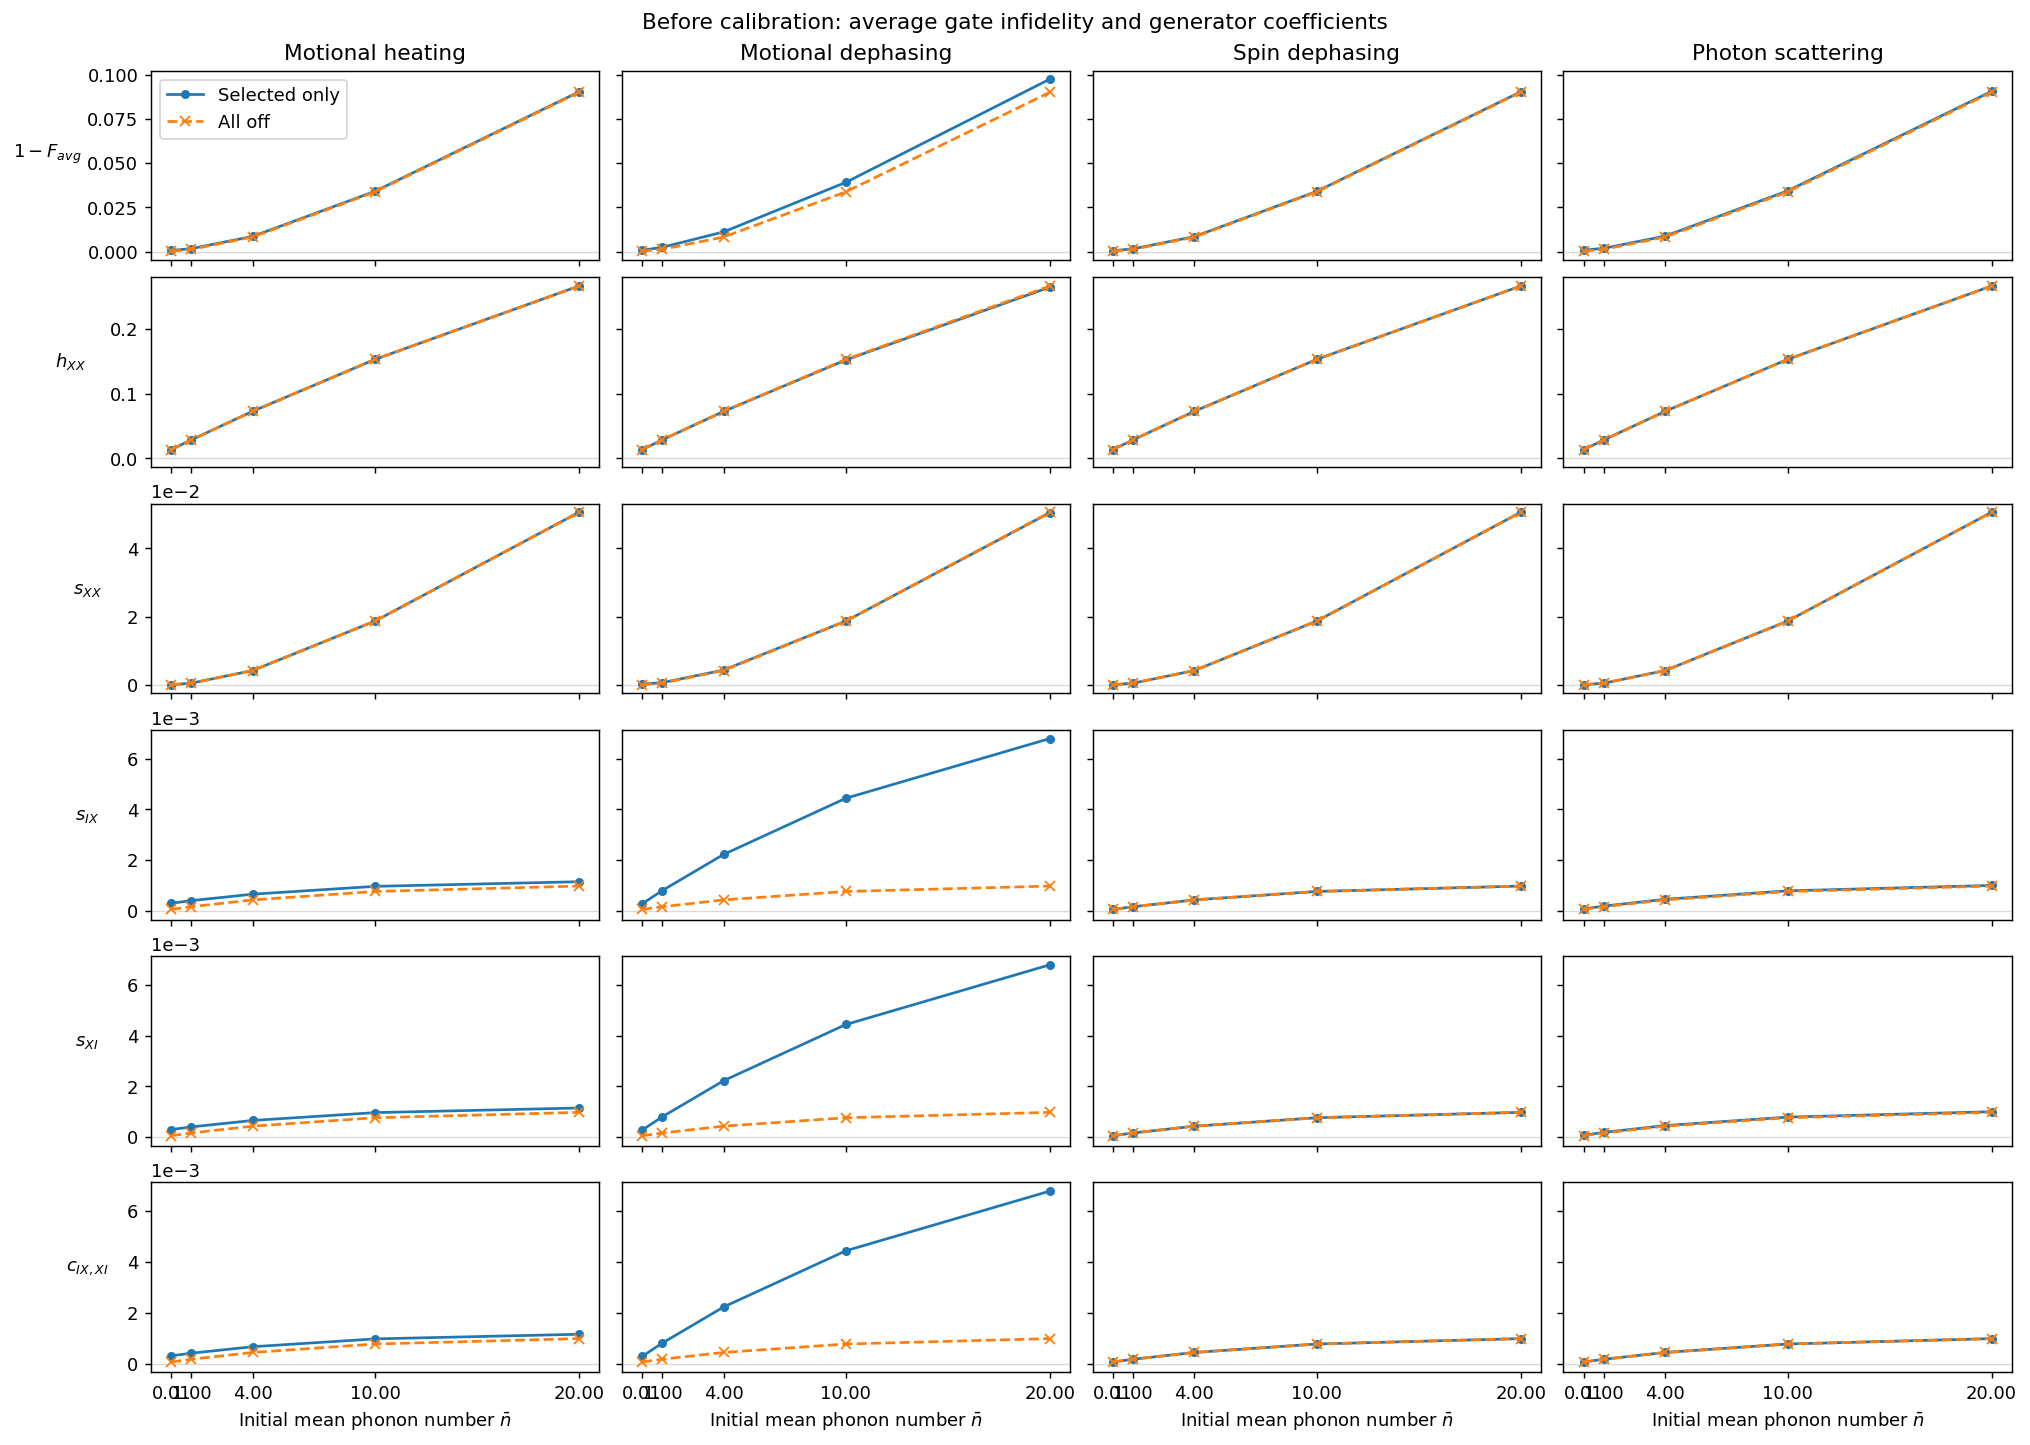

In [13]:
from drive_calibration_qpt_analysis import project_trace_normalized_chi_to_cptp

cache = Path("results/chi_error_element_fit/noise_source_ablation")

def read_sweep(condition):
    rows = {}
    for path in sorted(cache.glob(f"{condition}__nbar_*.npz")):
        with np.load(path) as data:
            nbar = float(data["n_bar"].item())
            channel, projected_chi, _ = project_trace_normalized_chi_to_cptp(data["chi_trace_normalized"])
        fit = _decompose_generator_taxonomy(logm(superoperator_to_ptm(channel)).real)
        rows[nbar] = {f"{s}:{m}": v for (s, m), v in zip(fit["metadata"], fit["coefficients"])}
        rows[nbar]["infidelity"] = 4 / 5 * (1 - projected_chi[0, 0].real)
    if not rows:
        raise FileNotFoundError(f"No saved channels for {condition} in {cache}")
    return pd.DataFrame.from_dict(rows, orient="index").sort_index()

off = read_sweep("none")
metrics = ["infidelity", *required]
fig, axs = plt.subplots(len(metrics), len(selected), squeeze=False, sharex=True, sharey="row",
                        figsize=(1.5 + 3.5 * len(selected), 11), layout="constrained")
for col, noise in enumerate(selected):
    on = read_sweep(f"only__{noise}")
    if not on.index.equals(off.index):
        raise ValueError(f"ON/OFF phonon grids differ for {noise}")
    axs[0, col].set_title(noise_titles[noise])
    for row, term in enumerate(metrics):
        ax = axs[row, col]
        ax.axhline(0, color="0.85", lw=0.7)
        ax.plot(on.index, on[term], "o-", ms=4, label="Selected only")
        ax.plot(off.index, off[term], "x--", ms=5, label="All off")
        ax.ticklabel_format(axis="y", style="sci", scilimits=(-2, 2))
        if col == 0 and term == "infidelity":
            ax.set_ylabel(r"$1-F_{avg}$", rotation=0, labelpad=22)
        elif col == 0:
            sector, mode = term.split(":")
            ax.set_ylabel(rf"${sector.lower()}_{{{mode}}}$", rotation=0, labelpad=22)
    axs[-1, col].set_xticks(on.index)
    axs[-1, col].set_xlabel(r"Initial mean phonon number $\bar n$")
axs[0, 0].legend()
fig.suptitle("Before calibration: average gate infidelity and generator coefficients")
comparison_path = source.with_name(f"infidelity_and_isolated_noise_{NOISE_NAME}.png")
fig.savefig(comparison_path, dpi=130, bbox_inches="tight")
plt.close(fig)
from IPython.display import Image, display
display(Image(filename=str(comparison_path)))

## 単独ノイズの強度依存性
他の3種類は OFF。各曲線は同じ初期占有数の全 OFF との差。

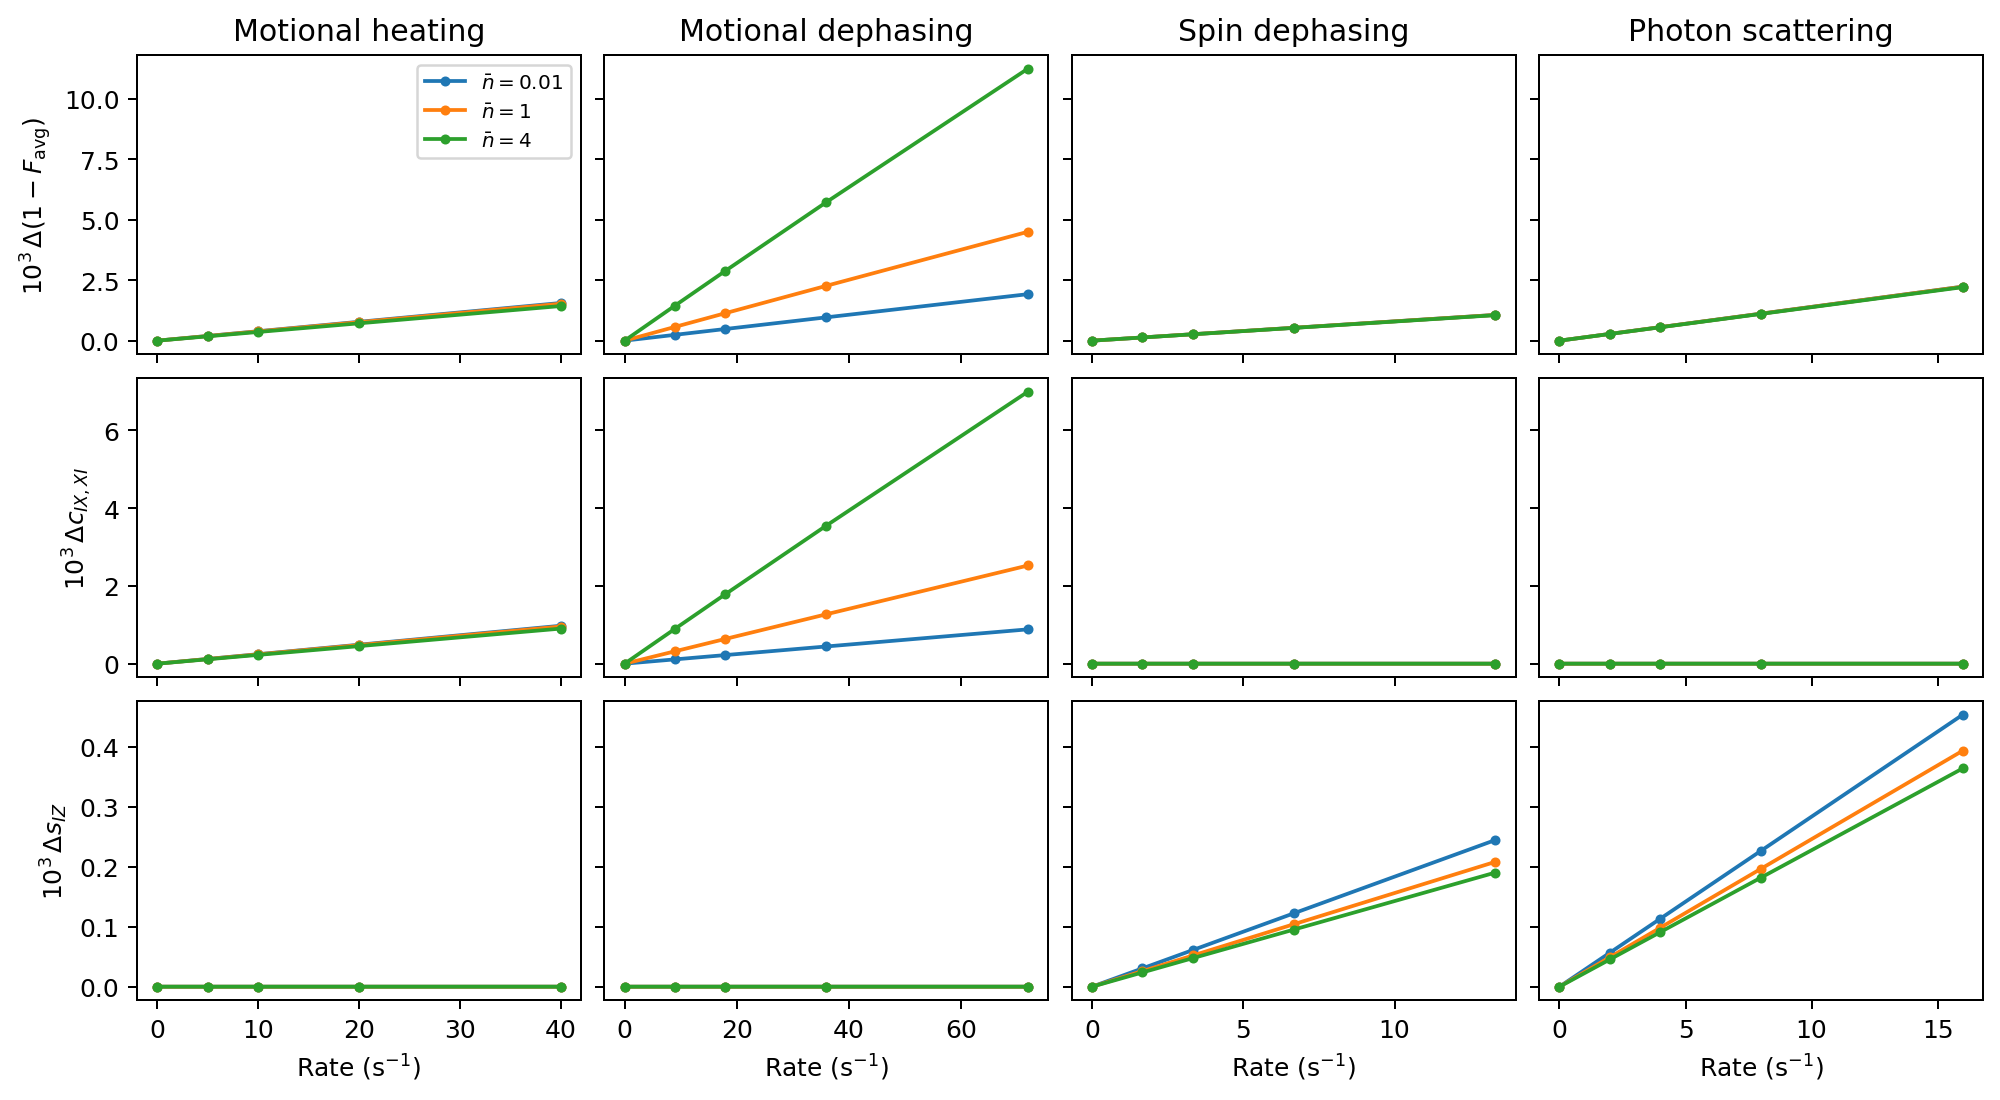

In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

rates = pd.read_csv("results/rate_hsca_structure/rate_hsca_coefficients.csv")
channels = pd.read_csv("results/error_generator_rate_nbar/top3_pairwise_generator/pairwise_generator_summary.csv")
sources = ["motional_heating", "motional_dephasing", "spin_dephasing", "photon_scattering"]
occupations = [0.01, 1, 4]
fig, axes = plt.subplots(3, 4, sharex="col", sharey="row", figsize=(11, 6), layout="constrained")
for col, noise in enumerate(sources):
    axes[0, col].set_title(noise.replace("_", " ").capitalize())
    other_rates = [f"{key}_s^-1" for key in sources if key != noise]
    isolated = channels[channels[other_rates].eq(0).all(axis=1)]
    for nbar in occupations:
        subset = rates[(rates.noise_source == noise) & (rates.nbar == nbar)]
        coeff = subset.pivot(index="rate_s^-1", columns=["sector", "mode"], values="coefficient_per_gate").sort_index()
        loss = isolated[isolated.nbar == nbar].set_index(f"{noise}_s^-1")["average_infidelity"].loc[coeff.index]
        for ax, values in zip(axes[:, col], [loss - loss.loc[0], coeff["C", "IX,XI"], coeff["S", "IZ"]]):
            ax.plot(coeff.index, 1000 * values, "o-", ms=3, label=rf"$\bar n={nbar:g}$")
    axes[-1, col].set_xlabel(r"Rate ($\mathrm{s}^{-1}$)")
for ax, label in zip(axes[:, 0], [r"$10^3\,\Delta(1-F_{\rm avg})$", r"$10^3\,\Delta c_{IX,XI}$", r"$10^3\,\Delta s_{IZ}$"]):
    ax.set_ylabel(label)
axes[0, 0].legend(fontsize=8)
target = Path("figures/isolated_noise_strength")
target.parent.mkdir(exist_ok=True)
for ext in [".pdf", ".png"]:
    fig.savefig(target.with_suffix(ext), dpi=180, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(target.with_suffix(".png"))))


## 2種類のノイズ強度とインフィデリティの非加算性
他の2種類は OFF。両方 ON の値から各単独 ON の値を引き、全 OFF の値を足して基準をそろえる。

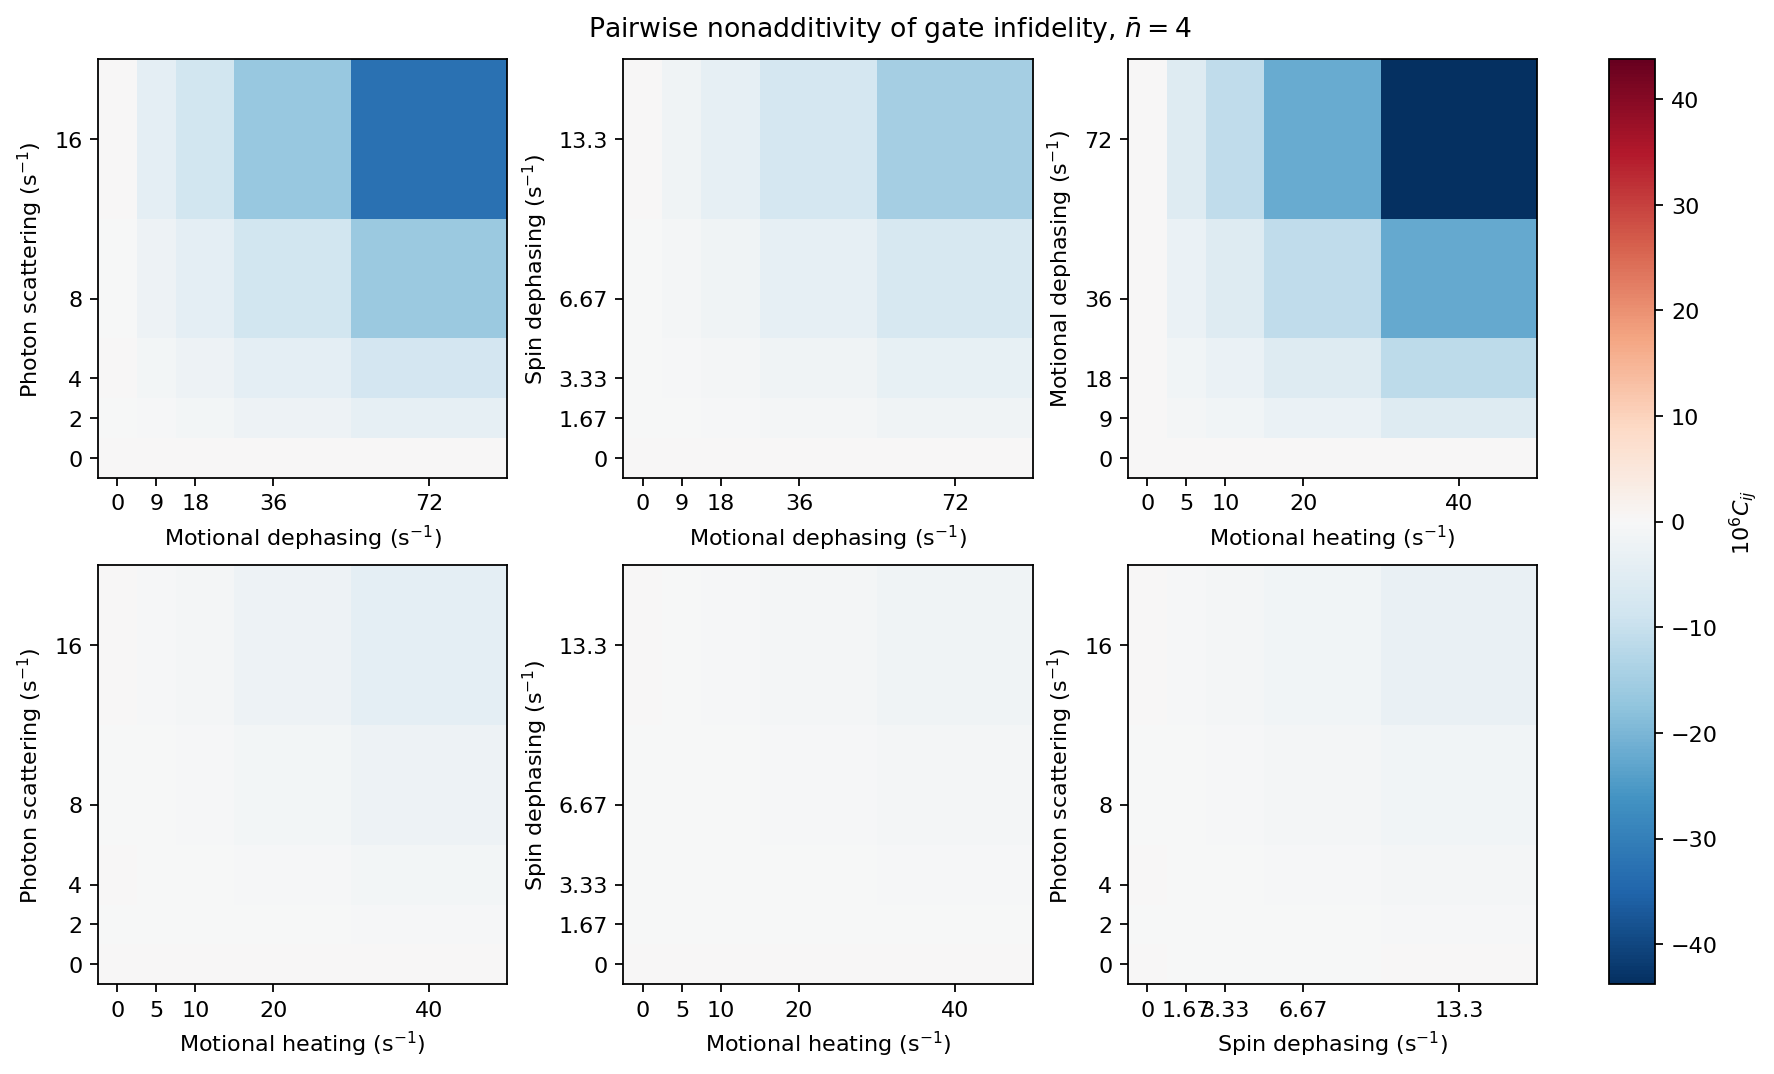

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

NBAR_PAIR = 4.0
folder = Path("results/noise_rate_nbar_sweep/all_pairwise_5x5_grids")
data = pd.read_csv(folder / "all_pairwise_grid_interactions.csv")
subset = data[data.nbar == NBAR_PAIR]
if subset.empty:
    raise ValueError(f"Available occupations: {sorted(data.nbar.unique())}")
fig, axes = plt.subplots(2, 3, figsize=(11, 6.6), layout="constrained")
limit = subset.interaction_infidelity.abs().max() * 1e6
for ax, (_, pair) in zip(axes.flat, subset.groupby("pair_id")):
    grid = pair.pivot(index="strength_y_s^-1", columns="strength_x_s^-1",
                      values="interaction_infidelity").sort_index().sort_index(axis=1)
    im = ax.pcolormesh(grid.columns, grid.index, grid.values * 1e6,
                       shading="nearest", cmap="RdBu_r", vmin=-limit, vmax=limit)
    for axis, key, ticks in [(ax.xaxis, "source_x", grid.columns), (ax.yaxis, "source_y", grid.index)]:
        axis.set_ticks(ticks)
        axis.set_ticklabels([f"{v:.3g}" for v in ticks])
        axis.set_label_text(pair[key].iloc[0].replace("_", " ").capitalize() + r" ($\mathrm{s}^{-1}$)")
fig.suptitle(rf"Pairwise nonadditivity of gate infidelity, $\bar n={NBAR_PAIR:g}$")
fig.colorbar(im, ax=axes, label=r"$10^6 C_{ij}$")
target = Path("figures") / f"pairwise_infidelity_nbar_{NBAR_PAIR:g}"
target.parent.mkdir(exist_ok=True)
for ext in [".pdf", ".png"]:
    fig.savefig(Path(str(target) + ext), dpi=160, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(target)+".png"))


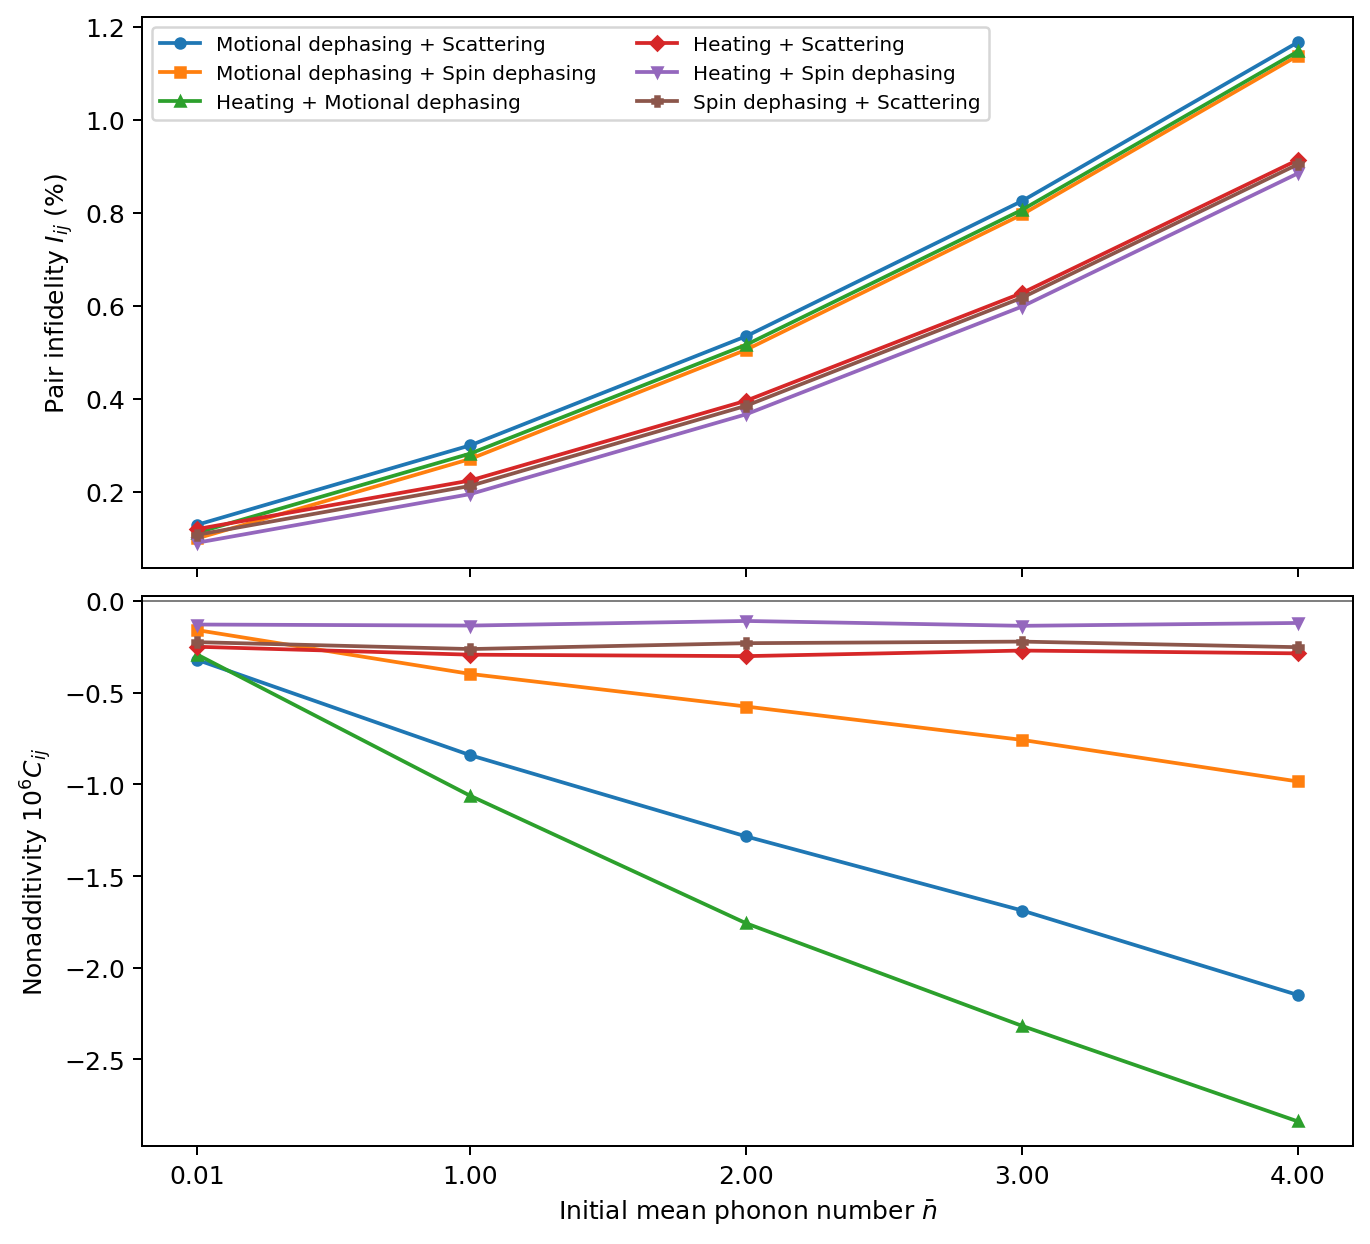

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

grid = pd.read_csv("results/noise_rate_nbar_sweep/all_pairwise_5x5_grids/all_pairwise_grid_interactions.csv")
nominal = grid.query("multiplier_x == 1 and multiplier_y == 1")
fig, (top, bottom) = plt.subplots(2, 1, sharex=True, figsize=(7.5, 6.8), layout="constrained")
names = {"motional_heating": "Heating", "motional_dephasing": "Motional dephasing",
         "spin_dephasing": "Spin dephasing", "photon_scattering": "Scattering"}
for (_, pair), marker in zip(nominal.groupby("pair_id"), "os^DvP"):
    pair = pair.sort_values("nbar")
    x = pair.nbar
    label = names[pair.source_x.iloc[0]] + " + " + names[pair.source_y.iloc[0]]
    top.plot(x, 100 * pair.grid_infidelity, marker=marker, label=label, ms=4)
    c = pair.grid_infidelity - pair.x_only_infidelity - pair.y_only_infidelity + pair.zero_infidelity
    np.testing.assert_allclose(c, pair.interaction_infidelity, atol=1e-14)
    bottom.plot(x, 1e6 * c, marker=marker, ms=4)
top.set_ylabel(r"Pair infidelity $I_{ij}$ (%)")
bottom.set_ylabel(r"Nonadditivity $10^6 C_{ij}$")
bottom.set_xlabel(r"Initial mean phonon number $\bar n$")
bottom.set_xticks(sorted(nominal.nbar.unique()))
bottom.axhline(0, color="0.5", lw=0.8)
top.legend(ncol=2, fontsize=8)
out = Path("figures/pair_infidelity_and_nonadditivity")
out.parent.mkdir(exist_ok=True)
for suffix in (".pdf", ".png"):
    fig.savefig(out.with_suffix(suffix), dpi=180, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(out.with_suffix(".png"))))
